# Standardized Genre Analysis and Visualizations

This notebook compares Netflix and Disney+ using the standardized broad genres created in Notebook 6.

The primary measure is title-presence percentage:

Title-presence percentage =
unique titles assigned to a broad genre
divided by all titles on the platform
multiplied by 100.

A title may belong to multiple broad genres, so genre-presence percentages do not add to 100%.

The analysis also uses fractional genre shares as a sensitivity check. Genre findings will be treated as supporting evidence for the project's primary geographic-concentration story.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
PROCESSED_DATA_DIR = Path("../data/processed")
OUTPUT_TABLE_DIR = Path("../outputs/tables")

FIGURE_DIR = Path(
    "../outputs/figures/notebook_07_genre_v1"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [4]:
titles = pd.read_csv(
    PROCESSED_DATA_DIR / "streaming_titles_clean.csv",
    parse_dates=["date_added"]
)

standardized_genres = pd.read_csv(
    PROCESSED_DATA_DIR
    / "streaming_titles_by_standardized_genre.csv",
    parse_dates=["date_added"]
)

mapping_coverage = pd.read_csv(
    OUTPUT_TABLE_DIR / "genre_mapping_coverage.csv"
)

genre_presence = pd.read_csv(
    OUTPUT_TABLE_DIR / "genre_presence_summary.csv"
)

genre_fractional = pd.read_csv(
    OUTPUT_TABLE_DIR / "genre_fractional_summary.csv"
)

print("Titles:", titles.shape)
print("Standardized genre relationships:", standardized_genres.shape)
print(
    "Unique mapped titles:",
    standardized_genres["content_id"].nunique()
)

display(mapping_coverage)

Titles: (10257, 16)
Standardized genre relationships: (17069, 12)
Unique mapped titles: 10169


,platform,total_titles,mapped_titles,unmapped_titles,coverage_percentage
0,Disney+,1450,1444,6,99.59
1,Netflix,8807,8725,82,99.07


In [6]:
coverage_difference = (
    mapping_coverage["coverage_percentage"].max()
    - mapping_coverage["coverage_percentage"].min()
)

print(
    "Difference in platform mapping coverage:",
    f"{coverage_difference:.2f} percentage points"
)

if coverage_difference <= 5:
    print(
        "Coverage is reasonably comparable between platforms."
    )
else:
    print(
        "Warning: Mapping coverage differs by more than "
        "five percentage points. Interpret genre comparisons "
        "carefully."
    )

Difference in platform mapping coverage: 0.52 percentage points
Coverage is reasonably comparable between platforms.


In [7]:
sns.set_theme(
    style="whitegrid",
    context="talk"
)

PLATFORM_COLORS = {
    "Netflix": "#E50914",
    "Disney+": "#1939B7"
}

def save_figure(fig, filename, overwrite=False):
    output_path = FIGURE_DIR / filename

    if output_path.exists() and not overwrite:
        raise FileExistsError(
            f"{output_path} already exists. "
            "Use a new filename or set overwrite=True."
        )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    print(f"Saved: {output_path}")

In [9]:
genre_presence_pivot = (
    genre_presence
    .pivot(
        index="broad_genre",
        columns="platform",
        values="title_presence_percentage"
    )
    .fillna(0)
    .reset_index()
)

genre_presence_pivot.columns.name = None

genre_presence_pivot[
    "disney_minus_netflix"
] = (
    genre_presence_pivot["Disney+"]
    - genre_presence_pivot["Netflix"]
).round(2)

genre_presence_pivot[
    "average_presence"
] = (
    genre_presence_pivot[
        ["Disney+", "Netflix"]
    ].mean(axis=1)
)

display(
    genre_presence_pivot.sort_values(
        "average_presence",
        ascending=False
    )
)

,broad_genre,Disney+,Netflix,disney_minus_netflix,average_presence
2,Children and Family,62.83,13.14,49.69,37.985
3,Comedy,36.76,29.75,7.01,33.255
6,Drama,24.76,36.22,-11.46,30.490
0,Action and Adventure,32.07,11.66,20.41,21.865
1,Animation and Anime,37.38,2.80,34.58,20.090
5,Documentary,23.86,14.40,9.46,19.130
12,Science Fiction and Fantasy,19.38,3.71,15.67,11.545
4,Crime Mystery and Thriller,2.34,13.17,-10.83,7.755
11,Romance,1.59,11.20,-9.61,6.395
9,Music and Performing Arts,6.48,4.26,2.22,5.370


Saved: ..\outputs\figures\notebook_07_genre_v1\01_broad_genre_comparison.png


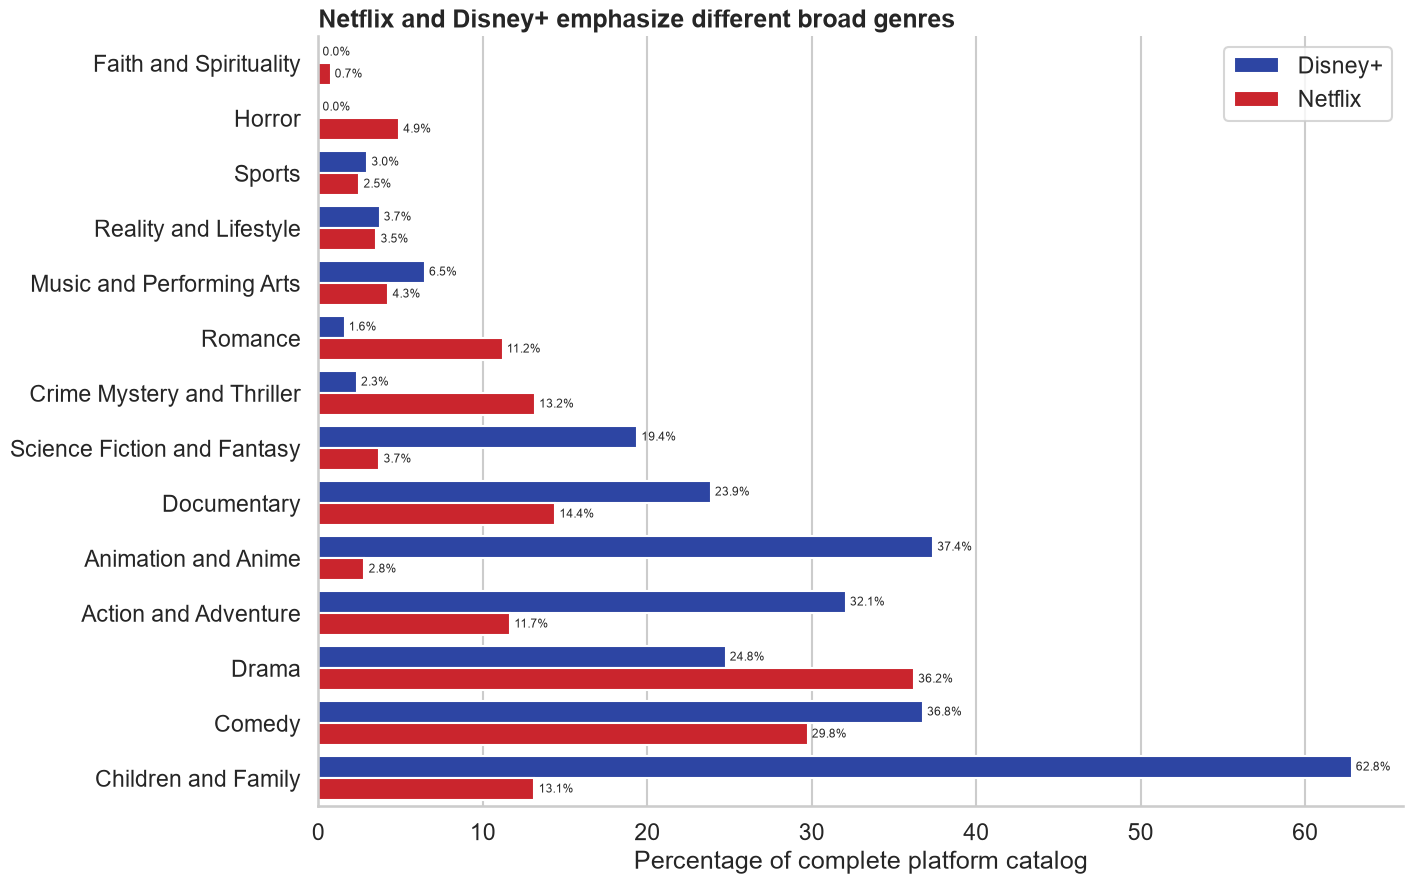

In [11]:
genre_order = (
    genre_presence_pivot
    .sort_values(
        "average_presence",
        ascending=True
    )["broad_genre"]
    .tolist()
)

genre_presence_long = (
    genre_presence_pivot
    .melt(
        id_vars="broad_genre",
        value_vars=["Disney+", "Netflix"],
        var_name="platform",
        value_name="title_presence_percentage"
    )
)

fig, ax = plt.subplots(figsize=(14, 10))

sns.barplot(
    data=genre_presence_long,
    y="broad_genre",
    x="title_presence_percentage",
    hue="platform",
    order=genre_order,
    hue_order=["Disney+", "Netflix"],
    palette=PLATFORM_COLORS,
    ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
        fontsize=8.5
    )

ax.set_title(
    "Netflix and Disney+ emphasize different broad genres",
    loc="left",
    fontsize=18,
    fontweight="bold"
)

ax.set_xlabel("Percentage of complete platform catalog")
ax.set_ylabel("")
ax.legend(
    title="",
    loc="upper right"
)

sns.despine(ax=ax)

save_figure(
    fig,
    "01_broad_genre_comparison.png"
)

plt.show()

Saved: ..\outputs\figures\notebook_07_genre_v1\02_genre_percentage_point_gaps.png


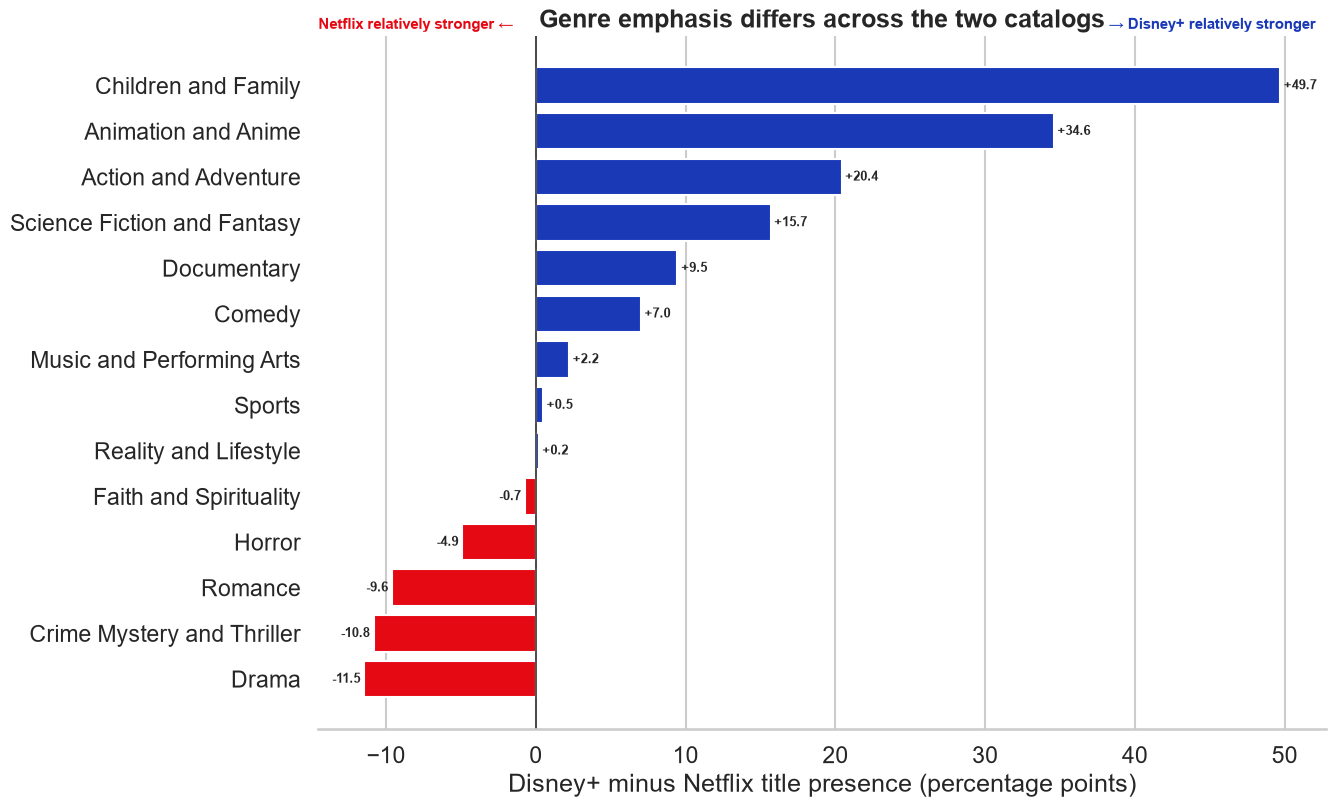

In [14]:
genre_gap = (
    genre_presence_pivot
    .sort_values("disney_minus_netflix")
    .copy()
)
gap_colors = [
    PLATFORM_COLORS["Disney+"]
    if value > 0
    else PLATFORM_COLORS["Netflix"]
    for value in genre_gap["disney_minus_netflix"]
]

fig, ax = plt.subplots(figsize=(13, 9))

bars = ax.barh(
    genre_gap["broad_genre"],
    genre_gap["disney_minus_netflix"],
    color=gap_colors
)

ax.axvline(
    0,
    color="#333333",
    linewidth=1.2
)

for bar, value in zip(
    bars,
    genre_gap["disney_minus_netflix"]
):
    if value >= 0:
        x_position = value + 0.25
        alignment = "left"
    else:
        x_position = value - 0.25
        alignment = "right"

    ax.text(
        x_position,
        bar.get_y() + bar.get_height() / 2,
        f"{value:+.1f}",
        va="center",
        ha=alignment,
        fontsize=9,
        fontweight="bold"
    )

ax.set_title(
    "Genre emphasis differs across the two catalogs",
    loc="Center",
    fontsize=18,
    fontweight="bold"
)

ax.set_xlabel(
    "Disney+ minus Netflix title presence "
    "(percentage points)"
)

ax.set_ylabel("")

ax.text(
    0.0,
    1.01,
    "Netflix relatively stronger ←",
    transform=ax.transAxes,
    color=PLATFORM_COLORS["Netflix"],
    fontsize=11,
    fontweight="bold",
    ha="left"
)

ax.text(
    0.99,
    1.01,
    "→ Disney+ relatively stronger",
    transform=ax.transAxes,
    color=PLATFORM_COLORS["Disney+"],
    fontsize=11,
    fontweight="bold",
    ha="right"
)

ax.grid(axis="y", visible=False)
sns.despine(ax=ax, left=True)

save_figure(
    fig,
    "02_genre_percentage_point_gaps.png"
)

plt.show()


In [15]:
platform_type_totals = (
    titles
    .groupby(["platform", "type"])
    .agg(
        total_titles=("content_id", "nunique")
    )
    .reset_index()
)

genre_by_type = (
    standardized_genres
    .groupby(
        ["platform", "type", "broad_genre"]
    )
    .agg(
        unique_titles=("content_id", "nunique")
    )
    .reset_index()
)

genre_by_type = genre_by_type.merge(
    platform_type_totals,
    on=["platform", "type"],
    how="left"
)

genre_by_type[
    "title_presence_percentage"
] = (
    genre_by_type["unique_titles"]
    / genre_by_type["total_titles"]
    * 100
).round(2)

genre_type_pivot = (
    genre_by_type
    .pivot_table(
        index="broad_genre",
        columns=["platform", "type"],
        values="title_presence_percentage",
        fill_value=0
    )
)

genre_type_gaps = pd.DataFrame(
    index=genre_type_pivot.index
)

for content_type in ["Movie", "TV Show"]:
    genre_type_gaps[content_type] = (
        genre_type_pivot[
            ("Disney+", content_type)
        ]
        - genre_type_pivot[
            ("Netflix", content_type)
        ]
    )

genre_type_gaps = genre_type_gaps.round(2)

Saved: ..\outputs\figures\notebook_07_genre_v1\03_genre_gaps_by_content_type.png


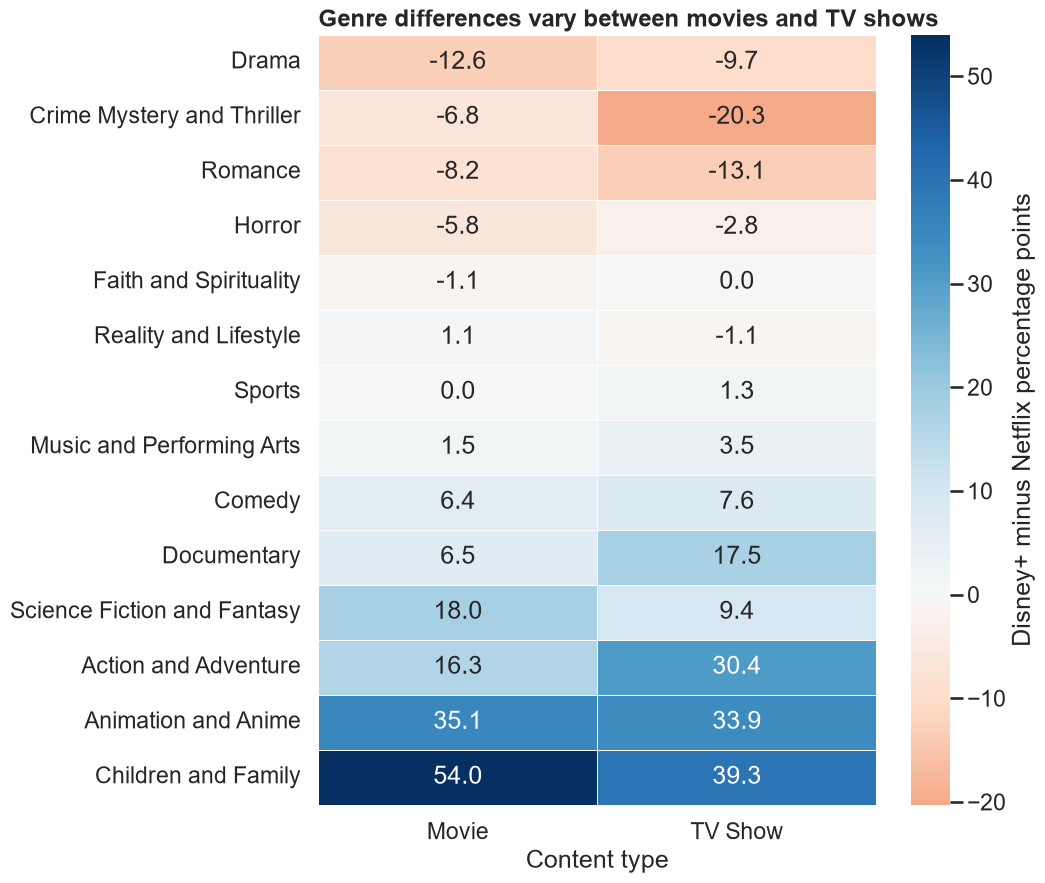

In [16]:
genre_type_gaps = genre_type_gaps.loc[
    genre_presence_pivot
    .set_index("broad_genre")
    .sort_values("disney_minus_netflix")
    .index
]

fig, ax = plt.subplots(figsize=(9, 10))

sns.heatmap(
    genre_type_gaps,
    cmap="RdBu",
    center=0,
    annot=True,
    fmt=".1f",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label":
        "Disney+ minus Netflix percentage points"
    },
    ax=ax
)

ax.set_title(
    "Genre differences vary between movies and TV shows",
    loc="left",
    fontsize=17,
    fontweight="bold"
)

ax.set_xlabel("Content type")
ax.set_ylabel("")

save_figure(
    fig,
    "03_genre_gaps_by_content_type.png"
)

plt.show()

In [18]:
fractional_pivot = (
    genre_fractional
    .pivot(
        index="broad_genre",
        columns="platform",
        values="fractional_share_percentage"
    )
    .fillna(0)
    .reset_index()
)

fractional_pivot.columns.name = None

fractional_pivot[
    "fractional_gap"
] = (
    fractional_pivot["Disney+"]
    - fractional_pivot["Netflix"]
).round(2)

genre_sensitivity = (
    genre_presence_pivot[
        [
            "broad_genre",
            "disney_minus_netflix"
        ]
    ]
    .merge(
        fractional_pivot[
            [
                "broad_genre",
                "fractional_gap"
            ]
        ],
        on="broad_genre",
        how="outer"
    )
    .fillna(0)
)

genre_sensitivity[
    "same_direction"
] = (
    np.sign(
        genre_sensitivity[
            "disney_minus_netflix"
        ]
    )
    == np.sign(
        genre_sensitivity[
            "fractional_gap"
        ]
    )
)

direction_agreement = (
    genre_sensitivity[
        "same_direction"
    ].mean() * 100
)

print(
    "Direction agreement between measures:",
    f"{direction_agreement:.1f}%"
)

gap_correlation = (
    genre_sensitivity[
        [
            "disney_minus_netflix",
            "fractional_gap"
        ]
    ]
    .corr()
    .iloc[0, 1]
)

print(
    "Correlation between gap measures:",
    f"{gap_correlation:.3f}"
)

display(
    genre_sensitivity[
        ~genre_sensitivity["same_direction"]
    ]
)

Direction agreement between measures: 78.6%
Correlation between gap measures: 0.905


,broad_genre,disney_minus_netflix,fractional_gap,same_direction
3,Comedy,7.01,-6.35,False
10,Reality and Lifestyle,0.19,-0.93,False
13,Sports,0.48,-0.01,False


Saved: ..\outputs\figures\notebook_07_genre_v1\04_genre_measure_sensitivity.png


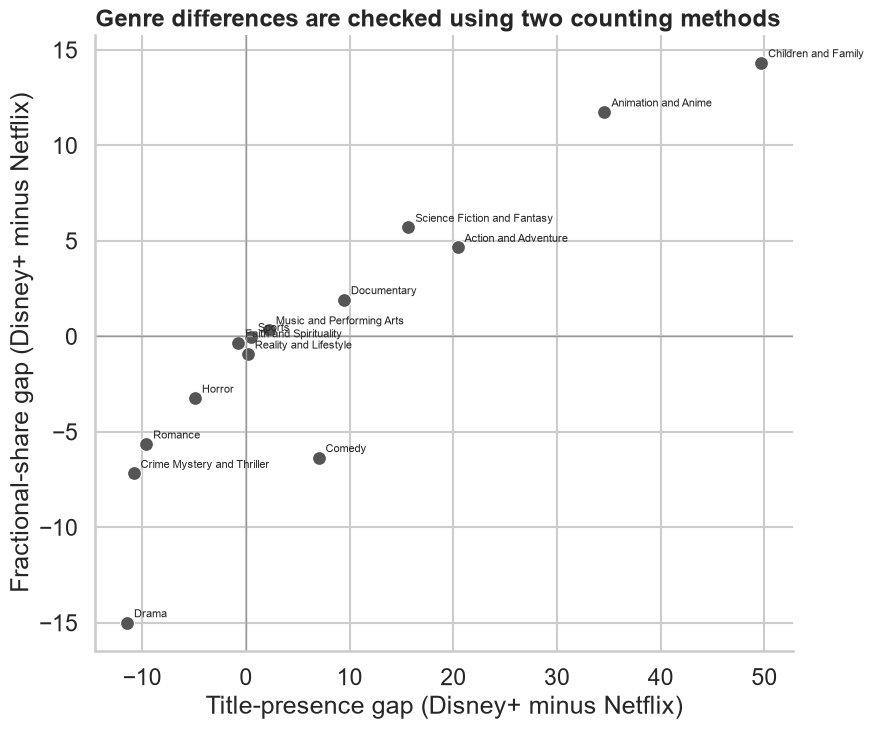

In [19]:
fig, ax = plt.subplots(figsize=(9, 8))

sns.scatterplot(
    data=genre_sensitivity,
    x="disney_minus_netflix",
    y="fractional_gap",
    s=100,
    color="#555555",
    ax=ax
)

ax.axhline(
    0,
    color="#999999",
    linewidth=1
)

ax.axvline(
    0,
    color="#999999",
    linewidth=1
)

for _, row in genre_sensitivity.iterrows():
    ax.annotate(
        row["broad_genre"],
        (
            row["disney_minus_netflix"],
            row["fractional_gap"]
        ),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8
    )

ax.set_title(
    "Genre differences are checked using two counting methods",
    loc="left",
    fontsize=17,
    fontweight="bold"
)

ax.set_xlabel(
    "Title-presence gap "
    "(Disney+ minus Netflix)"
)

ax.set_ylabel(
    "Fractional-share gap "
    "(Disney+ minus Netflix)"
)

sns.despine(ax=ax)

save_figure(
    fig,
    "04_genre_measure_sensitivity.png"
)

plt.show()

In [21]:
genre_comparison_final = (
    genre_presence_pivot[
        [
            "broad_genre",
            "Disney+",
            "Netflix",
            "disney_minus_netflix"
        ]
    ]
    .sort_values(
        "disney_minus_netflix",
        ascending=False
    )
)

display(genre_comparison_final)

disney_relative_strengths = (
    genre_comparison_final.head(3)
)

netflix_relative_strengths = (
    genre_comparison_final.tail(3)
    .sort_values("disney_minus_netflix")
)

print("Disney+ relative strengths:")
display(disney_relative_strengths)

print("Netflix relative strengths:")
display(netflix_relative_strengths)

,broad_genre,Disney+,Netflix,disney_minus_netflix
2,Children and Family,62.83,13.14,49.69
1,Animation and Anime,37.38,2.80,34.58
0,Action and Adventure,32.07,11.66,20.41
12,Science Fiction and Fantasy,19.38,3.71,15.67
5,Documentary,23.86,14.40,9.46
3,Comedy,36.76,29.75,7.01
9,Music and Performing Arts,6.48,4.26,2.22
13,Sports,2.97,2.49,0.48
10,Reality and Lifestyle,3.72,3.53,0.19
7,Faith and Spirituality,0.00,0.74,-0.74


Disney+ relative strengths:


,broad_genre,Disney+,Netflix,disney_minus_netflix
2,Children and Family,62.83,13.14,49.69
1,Animation and Anime,37.38,2.80,34.58
0,Action and Adventure,32.07,11.66,20.41


Netflix relative strengths:


,broad_genre,Disney+,Netflix,disney_minus_netflix
6,Drama,24.76,36.22,-11.46
4,Crime Mystery and Thriller,2.34,13.17,-10.83
11,Romance,1.59,11.20,-9.61


In [22]:
genre_comparison_final.to_csv(
    OUTPUT_TABLE_DIR
    / "standardized_genre_platform_comparison.csv",
    index=False
)

genre_by_type.to_csv(
    OUTPUT_TABLE_DIR
    / "standardized_genre_by_content_type.csv",
    index=False
)

genre_sensitivity.to_csv(
    OUTPUT_TABLE_DIR
    / "genre_measure_sensitivity.csv",
    index=False
)

## Notebook 7 Summary: Standardized Genre Comparison

This notebook compared the Netflix and Disney+ catalogs using standardized broad genre categories. Because the original platforms use different genre labels, a documented crosswalk was applied to group related labels into comparable categories such as **Children and Family**, **Animation and Anime**, **Drama**, and **Crime, Mystery, and Thriller**.

### Data and Mapping Coverage

The combined title dataset contains **10,257 records**, while the standardized genre table contains **17,069 title–genre relationships**. Titles may belong to multiple broad genres, so genre percentages represent the percentage of titles associated with each genre and do not add to 100%.

The genre mapping covered nearly all titles on both platforms:

- **Disney+:** 1,444 of 1,450 titles mapped — **99.59% coverage**
- **Netflix:** 8,725 of 8,807 titles mapped — **99.07% coverage**
- **Coverage difference:** only **0.52 percentage points**

Because both platforms achieved mapping coverage above 99%, their standardized genre results are reasonably comparable.

### Major Genre Differences

The analysis reveals clearly different catalog identities.

Disney+ has its largest relative advantages in:

- **Children and Family:** 62.83% of Disney+ titles compared with 13.14% of Netflix titles, a **49.69 percentage-point advantage**
- **Animation and Anime:** 37.38% compared with 2.80%, a **34.58-point advantage**
- **Action and Adventure:** 32.07% compared with 11.66%, a **20.41-point advantage**
- **Science Fiction and Fantasy:** 19.38% compared with 3.71%, a **15.67-point advantage**

Netflix has its largest relative advantages in:

- **Drama:** 36.22% of Netflix titles compared with 24.76% of Disney+ titles, an **11.46 percentage-point advantage**
- **Crime, Mystery, and Thriller:** 13.17% compared with 2.34%, a **10.83-point advantage**
- **Romance:** 11.20% compared with 1.59%, a **9.61-point advantage**
- **Horror:** 4.91% compared with no mapped Disney+ titles in this category

These results suggest that Disney+ has a highly focused family-entertainment identity, while Netflix offers a broader selection of mature dramatic, romantic, crime, thriller, and horror content.

### Differences by Content Type

Separating movies and television shows confirmed that the major genre differences are not caused only by differences in content-type composition.

Disney+'s advantage in **Children and Family** content was especially large among movies, while its advantages in **Animation and Anime** appeared in both movies and television. Disney+ also had a particularly strong advantage in television-based **Action and Adventure** and **Documentary** content.

Netflix maintained advantages in **Drama**, **Romance**, and **Crime, Mystery, and Thriller** among both movies and television shows. Its largest content-type-specific advantage appeared in crime, mystery, and thriller television programming.

### Sensitivity Analysis

A sensitivity analysis compared title-presence percentages with a fractional-counting method. The two methods produced:

- A **0.905 correlation**
- The same directional conclusion for **78.6% of broad genres**

This indicates that the principal genre findings are robust. The strongest conclusions—Disney+'s advantages in family, animation, action, and fantasy and Netflix's advantages in drama, crime, and romance—remain consistent.

Comedy, Reality and Lifestyle, and Sports produced smaller or method-sensitive differences. These categories should therefore not be emphasized as major strategic distinctions between the platforms.

### Overall Interpretation

The genre analysis supports the broader catalog story developed in the previous notebooks. Disney+ appears to follow a focused differentiation strategy built around children, families, animation, franchises, adventure, and fantasy. Netflix appears to follow a scale-and-variety strategy, providing more dramatic and mature genres to a broader international audience.

Together with the earlier geographic analysis, these results suggest a possible strategic opportunity for Disney+: expand the international diversity of its catalog while preserving its recognizable family-oriented and franchise-centered brand identity. Any expansion recommendation should be supported by additional research into audience demand, licensing availability, and acquisition costs.